# AI 생성 글 vs 인간 작성 글: 문체적 판별 요인 분석

이 노트북은 `docs/research_design.md`에서 정의한 연구 설계를 그대로 구현한 **엔드투엔드 분석
파이프라인**이다. Human/AI JSONL 데이터를 불러와 30개 feature를 추출하고, 통계 검정·PCA·
머신러닝(Logistic Regression / Decision Tree / Random Forest)·Permutation Importance·SHAP·
ANN·group-aware cross validation·강건성 검증까지 순서대로 실행한다.

> **⚠️ 지금 이 노트북을 실행하면 어떤 데이터가 쓰이는가?**
>
> 실제 연구가 목표로 하는 Human 300 + AI 300 = 600개의 검증된 matched-pair 코퍼스는 아직
> 완성되지 않았다 (`docs/research_design.md` §3.3, §12 참고 — 이 저장소가 만들어진 세션은
> 네트워크 정책상 원문 대조 검증을 위한 웹 접근이 차단되어 있었다). 그래서 이 노트북은
> 기본값으로 **`data/sample_synthetic/synthetic_test_data.jsonl`** (사람이 절차적으로 만든
> 30쌍짜리 더미 텍스트, `group="synthetic_demo_human"/"synthetic_demo_ai"`)을 사용한다.
>
> **이 synthetic demo 데이터의 결과는 실제 AI/인간 문체 차이에 대한 연구 결과가 아니다.**
> 오직 "코드가 처음부터 끝까지 오류 없이 실행되고, 의도적으로 주입한 차이(문장 길이 변동성,
> 접속어 반복 등)를 파이프라인이 실제로 검출하는가"를 확인하는 용도다. 실제 연구 데이터가
> 준비되면 SECTION 3의 `USE_SYNTHETIC_DEMO = False`로 바꾸고 경로만 지정하면, 이 노트북
> 전체가 그대로 실제 분석에 재사용된다.
>
> 이 저장소에는 실제 서지정보가 확정된 Human 스타터 배치
> (`data/human_classic/batch01_human_classic.jsonl`, 12개)와 그에 대응하는 AI 생성 배치
> (`data/ai_generated/batch01_ai_generated.jsonl`, 12개)도 포함되어 있다. 다만 Human 배치는
> 저작권 규칙에 따라 원문 대조 검증 전까지 `excerpt_text`를 비워 두었기 때문에(§3.3), 이번
> 실행에서는 feature 분석에 사용하지 않았다 — 검증 후 `human_classic_full.jsonl` 형태로
> 채워 넣는 것이 다음 단계다.


In [1]:
# ============================================================
# SECTION 1. 환경 설정 및 라이브러리 설치
# ============================================================
# 이 프로젝트는 다음 라이브러리를 사용한다: numpy, pandas, scipy, scikit-learn,
# matplotlib, seaborn, statsmodels, nltk, shap, tensorflow(keras).
#
# 이미 설치되어 있다면 아래 설치 코드는 건드릴 필요가 없다. Google Colab 등
# 새 환경에서 처음 실행한다면 아래 주석을 해제해서 실행하자.

import sys
import subprocess

REQUIRED_PACKAGES = [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn",
    "statsmodels", "nltk", "shap", "tensorflow-cpu",
]

INSTALL_PACKAGES = False  # 처음 실행하는 환경이면 True로 바꾸세요.

if INSTALL_PACKAGES:
    for pkg in REQUIRED_PACKAGES:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", pkg])
    print("라이브러리 설치 완료")
else:
    print("SECTION 1: 라이브러리는 이미 설치되어 있다고 가정합니다 (INSTALL_PACKAGES=False).")


SECTION 1: 라이브러리는 이미 설치되어 있다고 가정합니다 (INSTALL_PACKAGES=False).


In [2]:
# ============================================================
# SECTION 2. import
# ============================================================
import os
import re
import sys
import json
import time
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, cross_val_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve,
)

import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# src/ 폴더의 build_ai_prompt / extract_features 를 불러오기 위해 경로를 잡는다.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from feature_extraction import extract_features, FEATURE_NAMES, FEATURE_DEFINITIONS
from prompt_builder import build_ai_prompt

RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("SECTION 2: import 완료")
print("PROJECT_ROOT =", PROJECT_ROOT)
print("RANDOM_STATE =", RANDOM_STATE)
print(f"feature 개수 = {len(FEATURE_NAMES)}")


SECTION 2: import 완료
PROJECT_ROOT = /home/user/Minbub_GUide/ai_human_stylometry
RANDOM_STATE = 42
feature 개수 = 30


/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## SECTION 3. 데이터 불러오기

`USE_SYNTHETIC_DEMO`만 바꾸면 실제 연구 데이터로 그대로 전환된다.

In [3]:
# ============================================================
# SECTION 3. JSONL/CSV 데이터 불러오기
# ============================================================
# 실제 600개(Human 300 + AI 300) 데이터가 준비되면 아래 두 줄만 바꾸면 된다:
#   USE_SYNTHETIC_DEMO = False
#   HUMAN_PATH = PROJECT_ROOT / "data" / "human_classic" / "human_classic_full.jsonl"
#   AI_PATH    = PROJECT_ROOT / "data" / "ai_generated"   / "ai_generated_full.jsonl"

USE_SYNTHETIC_DEMO = True

if USE_SYNTHETIC_DEMO:
    HUMAN_PATH = PROJECT_ROOT / "data" / "sample_synthetic" / "synthetic_test_data.jsonl"
    AI_PATH = PROJECT_ROOT / "data" / "sample_synthetic" / "synthetic_test_data.jsonl"
else:
    HUMAN_PATH = PROJECT_ROOT / "data" / "human_classic" / "human_classic_full.jsonl"
    AI_PATH = PROJECT_ROOT / "data" / "ai_generated" / "ai_generated_full.jsonl"


def load_jsonl(path: Path) -> list:
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"{path.name}의 {line_no}번째 줄이 올바른 JSON이 아닙니다: {e}")
    return records


if USE_SYNTHETIC_DEMO:
    _raw = load_jsonl(HUMAN_PATH)
    human_records = [r for r in _raw if r["group"] == "synthetic_demo_human"]
    ai_records = [r for r in _raw if r["group"] == "synthetic_demo_ai"]
else:
    human_records = load_jsonl(HUMAN_PATH)
    ai_records = load_jsonl(AI_PATH)

print(f"SECTION 3: 데이터 로딩 완료 (USE_SYNTHETIC_DEMO={USE_SYNTHETIC_DEMO})")
print("Human 레코드 수:", len(human_records))
print("AI 레코드 수   :", len(ai_records))


SECTION 3: 데이터 로딩 완료 (USE_SYNTHETIC_DEMO=True)
Human 레코드 수: 30
AI 레코드 수   : 30


## SECTION 4. 데이터 구조 확인

In [4]:
# ============================================================
# SECTION 4. 데이터 구조 확인
# ============================================================
human_df_raw = pd.DataFrame(human_records)
ai_df_raw = pd.DataFrame(ai_records)

print("=== Human 데이터 컬럼 ===")
print(list(human_df_raw.columns))
print("\n=== AI 데이터 컬럼 ===")
print(list(ai_df_raw.columns))
print(f"\nHuman: {len(human_df_raw)}행, AI: {len(ai_df_raw)}행")

display(human_df_raw.head(3))
display(ai_df_raw.head(3))


=== Human 데이터 컬럼 ===
['sample_id', 'pair_id', 'group', 'label', 'author', 'title', 'year', 'genre', 'domain', 'topic', 'purpose', 'audience', 'style', 'main_message', 'value_optional', 'original_language', 'excerpt_text', 'excerpt_char_count', 'excerpt_word_count', 'content_summary', 'argument_structure', 'source_location', 'source_url', 'copyright_status', 'selection_reason', 'verified', 'note']

=== AI 데이터 컬럼 ===
['sample_id', 'pair_id', 'group', 'label', 'ai_model', 'model_version', 'generation_date', 'temperature', 'prompt_id', 'genre', 'domain', 'topic', 'purpose', 'audience', 'style', 'main_message', 'generated_text', 'text_char_count', 'text_word_count', 'note']

Human: 30행, AI: 30행


,sample_id,pair_id,group,label,author,title,year,genre,domain,topic,...,excerpt_char_count,excerpt_word_count,content_summary,argument_structure,source_location,source_url,copyright_status,selection_reason,verified,note
0,SH001,SP001,synthetic_demo_human,0,SYNTHETIC_PLACEHOLDER,synthetic placeholder text on urban_planning,2020,explanatory,environment,urban_planning,...,547,105,"N/A (synthetic placeholder, not real research ...",N/A,N/A,,not_applicable_synthetic,synthetic pipeline-test data,False,SYNTHETIC DEMO DATA — NOT REAL RESEARCH DATA. ...
1,SH002,SP002,synthetic_demo_human,0,SYNTHETIC_PLACEHOLDER,synthetic placeholder text on renewable_energy,2020,narrative,history,renewable_energy,...,1531,282,"N/A (synthetic placeholder, not real research ...",N/A,N/A,,not_applicable_synthetic,synthetic pipeline-test data,False,SYNTHETIC DEMO DATA — NOT REAL RESEARCH DATA. ...
2,SH003,SP003,synthetic_demo_human,0,SYNTHETIC_PLACEHOLDER,synthetic placeholder text on childhood_memory,2020,reflection,economics,childhood_memory,...,975,186,"N/A (synthetic placeholder, not real research ...",N/A,N/A,,not_applicable_synthetic,synthetic pipeline-test data,False,SYNTHETIC DEMO DATA — NOT REAL RESEARCH DATA. ...


,sample_id,pair_id,group,label,ai_model,model_version,generation_date,temperature,prompt_id,genre,domain,topic,purpose,audience,style,main_message,generated_text,text_char_count,text_word_count,note
0,SA001,SP001,synthetic_demo_ai,1,synthetic_generator,n/a,2026-09-09,None,SYN-SP001,explanatory,environment,urban_planning,reflection,general_public,explanatory,N/A (synthetic placeholder),Urban planning is a subject that deserves care...,763,99,SYNTHETIC DEMO DATA — NOT REAL RESEARCH DATA. ...
1,SA002,SP002,synthetic_demo_ai,1,synthetic_generator,n/a,2026-09-09,None,SYN-SP002,narrative,history,renewable_energy,analysis,general_public,explanatory,N/A (synthetic placeholder),Renewable energy is a subject that deserves ca...,765,101,SYNTHETIC DEMO DATA — NOT REAL RESEARCH DATA. ...
2,SA003,SP003,synthetic_demo_ai,1,synthetic_generator,n/a,2026-09-09,None,SYN-SP003,reflection,economics,childhood_memory,narration,general_public,explanatory,N/A (synthetic placeholder),Childhood memory is a subject that deserves ca...,770,100,SYNTHETIC DEMO DATA — NOT REAL RESEARCH DATA. ...


## SECTION 5. Human/AI 데이터 품질 검사

In [5]:
# ============================================================
# SECTION 5. Human/AI 데이터 품질 검사
# ============================================================

def quality_report(df: pd.DataFrame, text_col: str, expected_label: int) -> dict:
    report = {}
    report["행 개수"] = len(df)
    report["label 값 종류"] = sorted(df["label"].unique().tolist())
    report["label이 기대값과 다른 행 수"] = int((df["label"] != expected_label).sum())
    report["pair_id 결측"] = int(df["pair_id"].isna().sum())
    report["pair_id 중복"] = int(df["pair_id"].duplicated().sum())
    report[f"{text_col} 비어있음"] = int((df[text_col].fillna("").str.strip() == "").sum())
    return report


human_quality = quality_report(human_df_raw, "excerpt_text", expected_label=0)
ai_quality = quality_report(ai_df_raw, "generated_text", expected_label=1)

print("Human 품질 리포트:")
print(json.dumps(human_quality, ensure_ascii=False, indent=2))
print("\nAI 품질 리포트:")
print(json.dumps(ai_quality, ensure_ascii=False, indent=2))

n_empty_human_text = human_quality["excerpt_text 비어있음"]
if n_empty_human_text > 0:
    print(
        f"\n주의: excerpt_text가 비어 있는 Human 샘플이 {n_empty_human_text}개 있습니다. "
        "이 샘플들은 SECTION 9에서 feature가 전부 NaN으로 계산되며, SECTION 11에서 "
        "분석 대상에서 제외됩니다 (원문 미검증 -> 저작권 규칙에 따라 feature 계산 불가)."
    )


Human 품질 리포트:
{
  "행 개수": 30,
  "label 값 종류": [
    0
  ],
  "label이 기대값과 다른 행 수": 0,
  "pair_id 결측": 0,
  "pair_id 중복": 0,
  "excerpt_text 비어있음": 0
}

AI 품질 리포트:
{
  "행 개수": 30,
  "label 값 종류": [
    1
  ],
  "label이 기대값과 다른 행 수": 0,
  "pair_id 결측": 0,
  "pair_id 중복": 0,
  "generated_text 비어있음": 0
}


## SECTION 6. pair matching 검사

Human에만 있는 pair_id: 없음
AI에만 있는 pair_id   : 없음
매칭된 pair 수         : 30


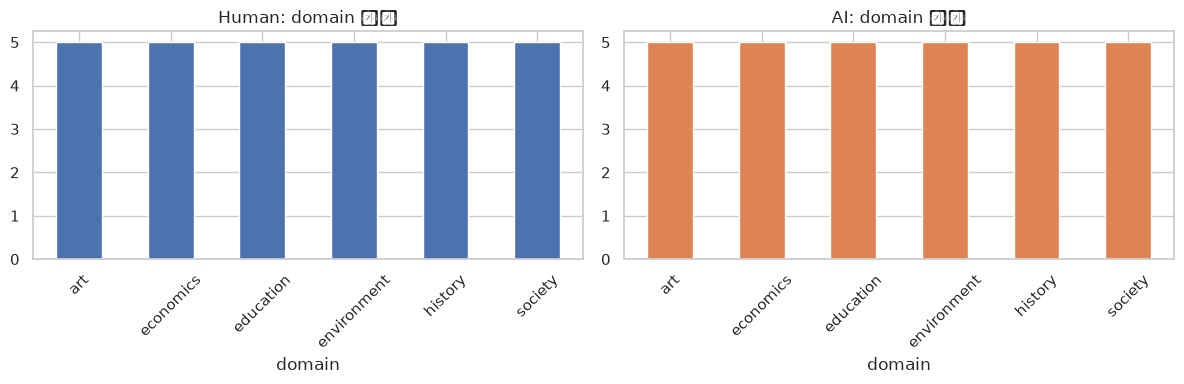

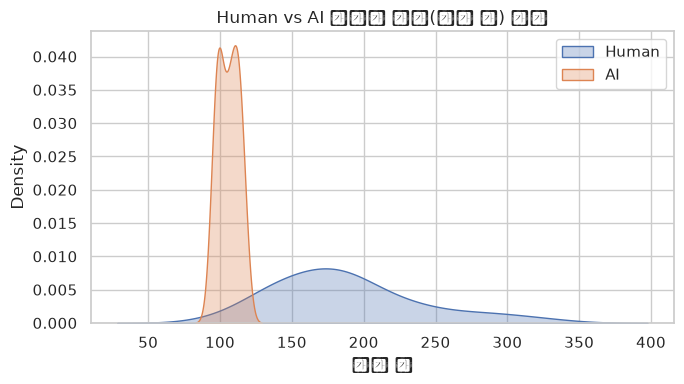

In [6]:
# ============================================================
# SECTION 6. pair matching 검사 (데이터 누수 방지의 첫 단계)
# ============================================================
human_pairs = set(human_df_raw["pair_id"])
ai_pairs = set(ai_df_raw["pair_id"])

only_human = human_pairs - ai_pairs
only_ai = ai_pairs - human_pairs
matched_pairs = human_pairs & ai_pairs

print("Human에만 있는 pair_id:", sorted(only_human) if only_human else "없음")
print("AI에만 있는 pair_id   :", sorted(only_ai) if only_ai else "없음")
print("매칭된 pair 수         :", len(matched_pairs))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
human_df_raw["domain"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Human: domain 분포")
axes[0].tick_params(axis="x", rotation=45)
ai_df_raw["domain"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("AI: domain 분포")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_pair_domain_balance.png", dpi=150)
plt.show()

# 텍스트 길이 분포도 함께 비교한다 (matched-pair 품질 점검).
human_len = human_df_raw["excerpt_text"].fillna("").str.split().apply(len)
ai_len = ai_df_raw["generated_text"].fillna("").str.split().apply(len)
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(human_len[human_len > 0], label="Human", ax=ax, fill=True, alpha=0.3)
sns.kdeplot(ai_len[ai_len > 0], label="AI", ax=ax, fill=True, alpha=0.3)
ax.set_xlabel("단어 수")
ax.set_title("Human vs AI 텍스트 길이(단어 수) 분포")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_length_distribution.png", dpi=150)
plt.show()


## SECTION 7. 텍스트 전처리

In [7]:
# ============================================================
# SECTION 7. 텍스트 전처리
# ============================================================

def detect_language(row: dict) -> str:
    lang = str(row.get("original_language") or row.get("language") or "en").lower()
    return "ko" if lang.startswith("ko") else "en"


def normalize_whitespace(t: str) -> str:
    return re.sub(r"\s+", " ", t).strip()


human_df_raw["text"] = human_df_raw["excerpt_text"].fillna("").apply(normalize_whitespace)
ai_df_raw["text"] = ai_df_raw["generated_text"].fillna("").apply(normalize_whitespace)
human_df_raw["language"] = human_df_raw.apply(detect_language, axis=1)
ai_df_raw["language"] = ai_df_raw.apply(detect_language, axis=1)

print("언어 분포 (Human):", human_df_raw["language"].value_counts().to_dict())
print("언어 분포 (AI)   :", ai_df_raw["language"].value_counts().to_dict())
print("\nSECTION 7 전처리 완료 (공백 정규화, 언어 태깅)")


언어 분포 (Human): {'en': 30}
언어 분포 (AI)   : {'en': 30}

SECTION 7 전처리 완료 (공백 정규화, 언어 태깅)


## SECTION 8. 30개 feature 추출 함수 정의 (`src/feature_extraction.py`) 확인

In [8]:
# ============================================================
# SECTION 8. 30개 feature extraction 함수 정의 확인
# ============================================================
# 실제 계산 로직은 src/feature_extraction.py 의 extract_features() 에 있다.
# 여기서는 각 feature의 정의·계산식·의미를 표로 확인만 한다 (연구설계 §19).

feature_def_df = pd.DataFrame(FEATURE_DEFINITIONS)
print(f"총 feature 개수: {len(feature_def_df)}")
display(feature_def_df[["id", "name", "category", "definition", "length_sensitive"]])


총 feature 개수: 30


,id,name,category,definition,length_sensitive
0,1,sentence_count,A_sentence_structure,텍스트 내 문장의 총 개수,True
1,2,avg_sentence_length,A_sentence_structure,문장 하나의 평균 단어 수,False
2,3,sentence_length_std,A_sentence_structure,문장별 단어 수의 표준편차,True
3,4,sentence_length_cv,A_sentence_structure,문장 길이의 변동계수 (표준편차 / 평균),False
4,5,max_sentence_length,A_sentence_structure,가장 긴 문장의 단어 수,True
5,6,min_sentence_length,A_sentence_structure,가장 짧은 문장의 단어 수,True
6,7,comma_rate,A_sentence_structure,문장당 평균 쉼표 개수,False
7,8,punctuation_rate,A_sentence_structure,"단어 100개당 구두점(.,!?;:—) 개수",False
8,9,word_count,B_lexical_diversity,총 단어(토큰) 수,True
9,10,unique_word_count,B_lexical_diversity,고유(중복 제거) 단어 수,True


## SECTION 9. 전체 데이터에 feature 적용

In [9]:
# ============================================================
# SECTION 9. 전체 데이터에 feature 적용
# ============================================================

def build_feature_rows(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, r in df.iterrows():
        feats = extract_features(r["text"], language=r["language"])
        rows.append(feats)
    feat_df = pd.DataFrame(rows)
    feat_df.index = df.index
    return feat_df


t0 = time.time()
human_features = build_feature_rows(human_df_raw)
ai_features = build_feature_rows(ai_df_raw)
elapsed = time.time() - t0

print(f"feature 추출 완료 ({elapsed:.1f}초)")
print("Human feature shape:", human_features.shape)
print("AI feature shape   :", ai_features.shape)


feature 추출 완료 (2.0초)
Human feature shape: (30, 31)
AI feature shape   : (30, 31)


## SECTION 10. feature DataFrame 생성 및 저장

In [10]:
# ============================================================
# SECTION 10. feature DataFrame 생성
# ============================================================
meta_cols = ["sample_id", "pair_id", "group", "label", "domain", "genre",
             "topic", "purpose", "audience", "style", "language"]

human_full = pd.concat(
    [human_df_raw[meta_cols].reset_index(drop=True), human_features.reset_index(drop=True)], axis=1
)
ai_full = pd.concat(
    [ai_df_raw[meta_cols].reset_index(drop=True), ai_features.reset_index(drop=True)], axis=1
)

feature_df = pd.concat([human_full, ai_full], axis=0, ignore_index=True)

# ai_model은 AI 샘플에만 존재하고 Human은 NaN (연구설계 §36)
ai_model_lookup = dict(zip(ai_df_raw["sample_id"], ai_df_raw.get("ai_model", pd.Series(dtype=str))))
feature_df["ai_model"] = feature_df["sample_id"].map(ai_model_lookup)

print("전체 feature_df shape:", feature_df.shape)
display(feature_df.head())

feature_df.to_csv(RESULTS_DIR / "processed_text_features.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", RESULTS_DIR / "processed_text_features.csv")


전체 feature_df shape: (60, 43)


,sample_id,pair_id,group,label,domain,genre,topic,purpose,audience,style,...,repeated_word_rate,repeated_bigram_rate,repeated_trigram_rate,sentence_start_repetition,conjunction_repetition_rate,three_item_enumeration_rate,sentiment_score,lexical_entropy,char_count,ai_model
0,SH001,SP001,synthetic_demo_human,0,environment,explanatory,urban_planning,reflection,general_public,narrative,...,0.253521,0.057692,0.000000,0.000000,0.400000,0.0,-0.6858,0.869859,547,NaN
1,SH002,SP002,synthetic_demo_human,0,history,narrative,renewable_energy,analysis,general_public,narrative,...,0.719101,0.814947,0.800000,0.625000,0.384615,2.5,-0.8608,0.745906,1531,NaN
2,SH003,SP003,synthetic_demo_human,0,economics,reflection,childhood_memory,narration,general_public,narrative,...,0.472527,0.443243,0.413043,0.125000,0.428571,0.0,-0.8591,0.807458,975,NaN
3,SH004,SP004,synthetic_demo_human,0,education,essay,local_folklore,information,general_public,narrative,...,0.581081,0.693122,0.670213,0.400000,0.400000,1.0,-0.8489,0.773734,1047,NaN
4,SH005,SP005,synthetic_demo_human,0,art,explanatory,coffee_trade,reflection,general_public,narrative,...,0.680851,0.807692,0.790698,0.333333,1.000000,0.0,-0.2057,0.752960,694,NaN


저장 완료: /home/user/Minbub_GUide/ai_human_stylometry/results/processed_text_features.csv


## SECTION 11. 결측치 및 이상치 검사

In [11]:
# ============================================================
# SECTION 11. 결측치 및 이상치 검사
# ============================================================
missing_counts = feature_df[FEATURE_NAMES].isna().sum()
print("feature별 결측치 개수:")
print(missing_counts[missing_counts > 0] if (missing_counts > 0).any() else "결측치 없음")

before_n = len(feature_df)
analysis_df = feature_df.dropna(subset=FEATURE_NAMES).copy()
after_n = len(analysis_df)
print(f"\n결측 feature가 있는 행 {before_n - after_n}개를 이후 분석에서 제외합니다. "
      f"(분석 대상 {after_n}행 / 전체 {before_n}행)")

z_scores = (analysis_df[FEATURE_NAMES] - analysis_df[FEATURE_NAMES].mean()) / analysis_df[FEATURE_NAMES].std(ddof=0).replace(0, np.nan)
outlier_counts = (z_scores.abs() > 4).sum()
print("\n|z-score| > 4 인 이상치 개수 (feature별, 있는 경우만):")
nonzero_outliers = outlier_counts[outlier_counts > 0]
print(nonzero_outliers if len(nonzero_outliers) else "이상치 없음")


feature별 결측치 개수:
결측치 없음

결측 feature가 있는 행 0개를 이후 분석에서 제외합니다. (분석 대상 60행 / 전체 60행)

|z-score| > 4 인 이상치 개수 (feature별, 있는 경우만):
이상치 없음


## SECTION 12. 기술통계

In [12]:
# ============================================================
# SECTION 12. 기술통계 (Human vs AI)
# ============================================================
desc_human = analysis_df[analysis_df["label"] == 0][FEATURE_NAMES].describe().T
desc_ai = analysis_df[analysis_df["label"] == 1][FEATURE_NAMES].describe().T

desc_compare = pd.DataFrame({
    "human_mean": desc_human["mean"], "human_std": desc_human["std"],
    "ai_mean": desc_ai["mean"], "ai_std": desc_ai["std"],
})
desc_compare["mean_diff(AI-Human)"] = desc_compare["ai_mean"] - desc_compare["human_mean"]
desc_compare = desc_compare.sort_values("mean_diff(AI-Human)", key=lambda s: s.abs(), ascending=False)
display(desc_compare)


,human_mean,human_std,ai_mean,ai_std,mean_diff(AI-Human)
word_count,187.333333,50.371265,105.700000,7.144566,-81.633333
unique_word_count,84.300000,15.051979,59.000000,6.074253,-25.300000
max_sentence_length,39.833333,2.118609,14.600000,0.621455,-25.233333
punctuation_rate,11.869850,1.769880,34.238188,2.553521,22.368338
sentence_length_std,15.124676,1.783469,1.634511,0.231163,-13.490165
avg_sentence_length,24.049762,4.076981,12.436111,0.418889,-11.613651
three_item_enumeration_rate,1.361243,1.462328,7.995370,0.975762,6.634127
min_sentence_length,4.800000,2.249904,9.866667,0.345746,5.066667
avg_word_length,4.298874,0.209618,6.301591,0.157896,2.002718
sentiment_score,-0.374140,0.587573,0.976037,0.019112,1.350177


## SECTION 13. 상관관계 분석 및 다중공선성 점검

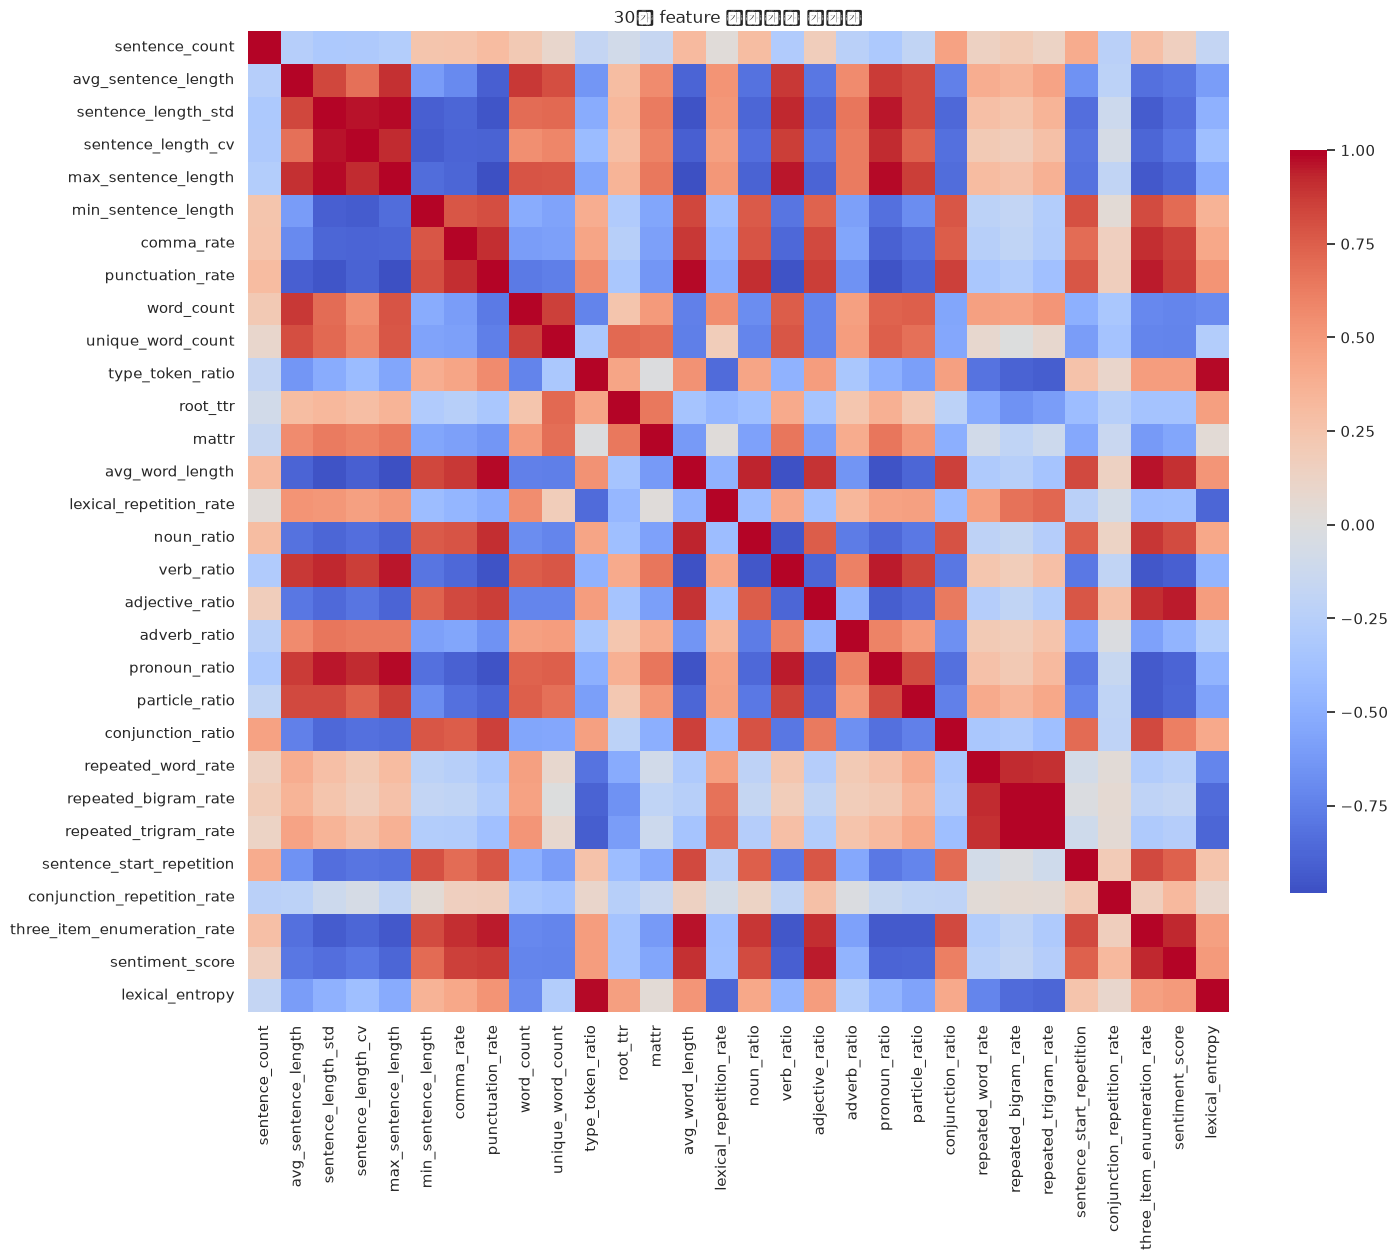

|r| > 0.85 인 변수쌍 (다중공선성 후보):
  avg_sentence_length <-> max_sentence_length: r=0.902
  avg_sentence_length <-> punctuation_rate: r=-0.911
  avg_sentence_length <-> word_count: r=0.884
  avg_sentence_length <-> avg_word_length: r=-0.888
  avg_sentence_length <-> verb_ratio: r=0.883
  avg_sentence_length <-> pronoun_ratio: r=0.869
  sentence_length_std <-> sentence_length_cv: r=0.966
  sentence_length_std <-> max_sentence_length: r=0.983
  sentence_length_std <-> min_sentence_length: r=-0.908
  sentence_length_std <-> comma_rate: r=-0.875
  sentence_length_std <-> punctuation_rate: r=-0.96
  sentence_length_std <-> avg_word_length: r=-0.966
  sentence_length_std <-> noun_ratio: r=-0.88
  sentence_length_std <-> verb_ratio: r=0.928
  sentence_length_std <-> adjective_ratio: r=-0.854
  sentence_length_std <-> pronoun_ratio: r=0.96
  sentence_length_std <-> conjunction_ratio: r=-0.862
  sentence_length_std <-> three_item_enumeration_rate: r=-0.924
  sentence_length_cv <-> max_sentence_length

,feature,VIF
9,unique_word_count,3512.023515
11,root_ttr,3496.016950
10,type_token_ratio,2628.937674
8,word_count,1722.508306
2,sentence_length_std,1286.607615
1,avg_sentence_length,1238.610936
7,punctuation_rate,1105.065447
23,repeated_bigram_rate,870.689166
3,sentence_length_cv,712.709815
19,pronoun_ratio,667.650553



참고: VIF > 10 은 심각한 다중공선성의 경험적 기준값이다. 상관이 높다고 해서 기계적으로 변수를 삭제하지 않고, 개념적 의미(예: word_count는 길이 통제 변수)를 함께 고려해 유지/제거를 판단한다 (연구설계 §8).


In [13]:
# ============================================================
# SECTION 13. 상관관계 분석
# ============================================================
corr_matrix = analysis_df[FEATURE_NAMES].corr()

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, ax=ax, square=True, cbar_kws={"shrink": 0.7})
ax.set_title("30개 feature 상관관계 히트맵")
plt.tight_layout()
plt.savefig(FIG_DIR / "13_correlation_heatmap.png", dpi=150)
plt.show()

high_corr_pairs = []
for i in range(len(FEATURE_NAMES)):
    for j in range(i + 1, len(FEATURE_NAMES)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.85:
            high_corr_pairs.append((FEATURE_NAMES[i], FEATURE_NAMES[j], round(float(r), 3)))

print("|r| > 0.85 인 변수쌍 (다중공선성 후보):")
if high_corr_pairs:
    for a, b, r in high_corr_pairs:
        print(f"  {a} <-> {b}: r={r}")
else:
    print("  없음")

# VIF(분산팽창지수) — 특이행렬 등으로 계산이 실패하는 feature는 NaN 처리한다.
X_vif = analysis_df[FEATURE_NAMES].copy()
X_vif = (X_vif - X_vif.mean()) / X_vif.std(ddof=0).replace(0, 1)
vif_values = []
for i in range(X_vif.shape[1]):
    try:
        vif_values.append(variance_inflation_factor(X_vif.values, i))
    except Exception:
        vif_values.append(np.nan)

vif_data = pd.DataFrame({"feature": FEATURE_NAMES, "VIF": vif_values}).sort_values("VIF", ascending=False)
display(vif_data.head(10))
print("\n참고: VIF > 10 은 심각한 다중공선성의 경험적 기준값이다. 상관이 높다고 해서 "
      "기계적으로 변수를 삭제하지 않고, 개념적 의미(예: word_count는 길이 통제 변수)를 "
      "함께 고려해 유지/제거를 판단한다 (연구설계 §8).")


## SECTION 14. AI vs Human feature 분포 비교

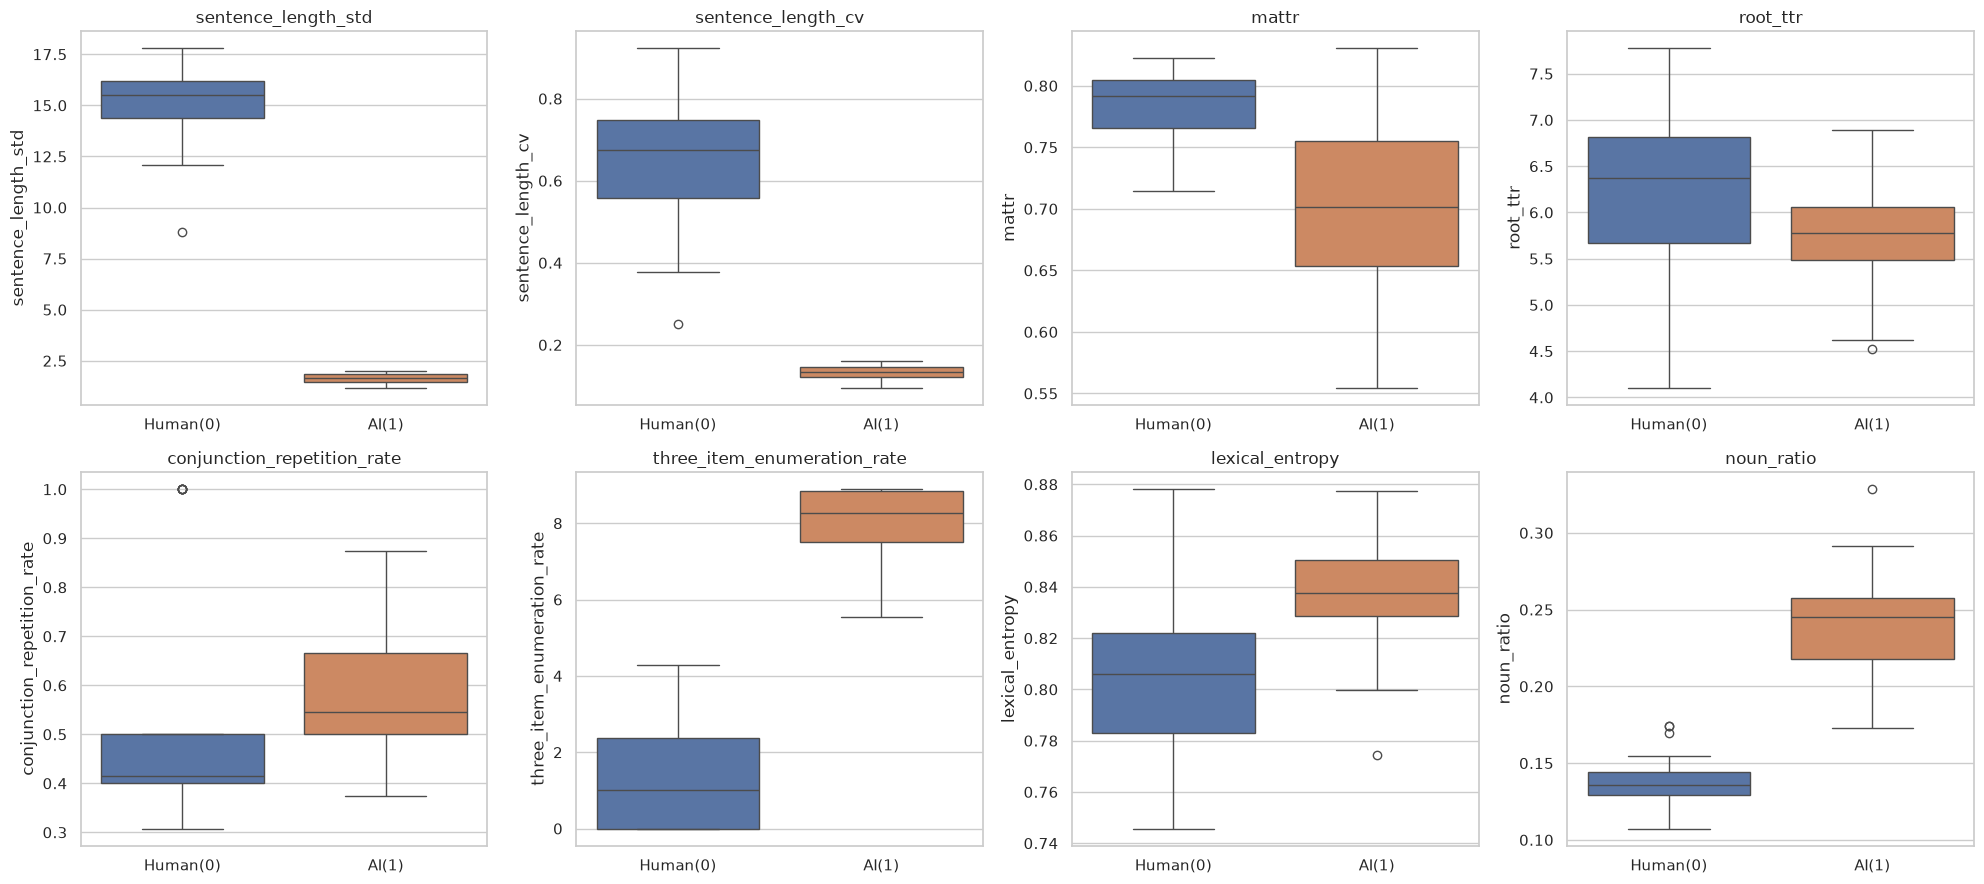

In [14]:
# ============================================================
# SECTION 14. AI vs Human feature 분포 비교
# ============================================================
key_features = [
    "sentence_length_std", "sentence_length_cv", "mattr", "root_ttr",
    "conjunction_repetition_rate", "three_item_enumeration_rate",
    "lexical_entropy", "noun_ratio",
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, feat in zip(axes.flat, key_features):
    sns.boxplot(data=analysis_df, x="label", y=feat, ax=ax,
                hue="label", palette={0: "#4C72B0", 1: "#DD8452"}, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Human(0)", "AI(1)"])
    ax.set_title(feat)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "14_key_features_boxplot.png", dpi=150)
plt.show()


## SECTION 15-17. Paired statistical tests, effect size, multiple testing correction

In [15]:
# ============================================================
# SECTION 15-17. pair 구조를 반영한 통계 검정 + effect size + FDR 보정
# ============================================================
# Human과 AI가 matched pair이므로 단순 independent t-test 대신,
# pair_id로 정렬한 뒤 paired t-test 또는 Wilcoxon signed-rank test를 사용한다.

human_side = analysis_df[analysis_df["label"] == 0]
ai_side = analysis_df[analysis_df["label"] == 1]
common_pairs = sorted(set(human_side["pair_id"]) & set(ai_side["pair_id"]))
print(f"paired test에 사용할 pair 수: {len(common_pairs)}")

human_wide = human_side.set_index("pair_id").loc[common_pairs, FEATURE_NAMES]
ai_wide = ai_side.set_index("pair_id").loc[common_pairs, FEATURE_NAMES]

results = []
for feat in FEATURE_NAMES:
    h = human_wide[feat].values.astype(float)
    a = ai_wide[feat].values.astype(float)
    diff = a - h
    n = len(diff)

    try:
        if n >= 3 and np.std(diff) > 0:
            _, p_norm = stats.shapiro(diff)
        else:
            p_norm = 0.0
    except Exception:
        p_norm = 0.0

    use_ttest = (p_norm > 0.05) and (n >= 8)
    try:
        if use_ttest:
            stat, p = stats.ttest_rel(a, h)
            test_name = "paired t-test"
            sd = diff.std(ddof=1)
            effect_size = diff.mean() / sd if sd > 0 else np.nan
            effect_name = "Cohen's d (paired)"
        else:
            if np.all(diff == 0):
                raise ValueError("모든 차이가 0")
            stat, p = stats.wilcoxon(a, h)
            test_name = "Wilcoxon signed-rank"
            max_w = n * (n + 1) / 2
            effect_size = 1 - (2 * stat) / max_w if max_w > 0 else np.nan
            effect_name = "rank-biserial r"
    except Exception as e:
        stat, p, effect_size = np.nan, 1.0, np.nan
        test_name = f"검정 실패({type(e).__name__})"
        effect_name = "N/A"

    results.append({
        "feature": feat, "human_mean": h.mean(), "ai_mean": a.mean(),
        "mean_diff(AI-Human)": diff.mean(), "test": test_name,
        "statistic": stat, "p_value": p,
        "effect_size": effect_size, "effect_size_type": effect_name,
    })

stat_df = pd.DataFrame(results)

reject, p_adj, _, _ = multipletests(stat_df["p_value"].fillna(1.0), alpha=0.05, method="fdr_bh")
stat_df["p_adjusted_fdr"] = p_adj
stat_df["significant_fdr_0.05"] = reject
stat_df = stat_df.sort_values("p_adjusted_fdr")

display(stat_df)
stat_df.to_csv(RESULTS_DIR / "statistical_tests.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", RESULTS_DIR / "statistical_tests.csv")
print(f"\nFDR 보정 후 유의(p<0.05)한 feature 수: {int(stat_df['significant_fdr_0.05'].sum())} / {len(stat_df)}")


paired test에 사용할 pair 수: 30


,feature,human_mean,ai_mean,mean_diff(AI-Human),test,statistic,p_value,effect_size,effect_size_type,p_adjusted_fdr,significant_fdr_0.05
13,avg_word_length,4.298874,6.301591,2.002718,paired t-test,48.296403,2.903616e-29,8.817677,Cohen's d (paired),8.710847e-28,True
7,punctuation_rate,11.869850,34.238188,22.368338,paired t-test,39.288511,1.058363e-26,7.173068,Cohen's d (paired),1.313028e-25,True
19,pronoun_ratio,0.104356,0.011507,-0.092848,paired t-test,-38.992179,1.313028e-26,-7.118965,Cohen's d (paired),1.313028e-25,True
16,verb_ratio,0.209259,0.114586,-0.094674,paired t-test,-25.045564,3.413043e-21,-4.572673,Cohen's d (paired),2.559782e-20,True
3,sentence_length_cv,0.652737,0.131326,-0.521410,paired t-test,-18.644095,1.090698e-17,-3.403930,Cohen's d (paired),6.544190e-17,True
1,avg_sentence_length,24.049762,12.436111,-11.613651,paired t-test,-15.819508,8.451091e-16,-2.888234,Cohen's d (paired),4.225545e-15,True
15,noun_ratio,0.137496,0.240214,0.102718,paired t-test,15.082448,2.915901e-15,2.753666,Cohen's d (paired),1.249672e-14,True
17,adjective_ratio,0.051679,0.118141,0.066462,paired t-test,14.650540,6.160318e-15,2.674810,Cohen's d (paired),2.310119e-14,True
6,comma_rate,1.811362,3.037037,1.225675,paired t-test,14.285601,1.174552e-14,2.608182,Cohen's d (paired),3.915175e-14,True
20,particle_ratio,0.173837,0.115254,-0.058584,paired t-test,-12.900816,1.530493e-13,-2.355356,Cohen's d (paired),4.591478e-13,True


저장 완료: /home/user/Minbub_GUide/ai_human_stylometry/results/statistical_tests.csv

FDR 보정 후 유의(p<0.05)한 feature 수: 28 / 30


## SECTION 18. StandardScaler

In [16]:
# ============================================================
# SECTION 18. 표준화 (StandardScaler)
# ============================================================
X_all = analysis_df[FEATURE_NAMES].values
y_all = analysis_df["label"].values
groups_all = analysis_df["pair_id"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

print("표준화 완료. X_scaled shape:", X_scaled.shape)
print("클래스 분포:", pd.Series(y_all).value_counts().to_dict())


표준화 완료. X_scaled shape: (60, 30)
클래스 분포: {0: 30, 1: 30}


## SECTION 19-20. PCA 및 시각화

In [17]:
# ============================================================
# SECTION 19. PCA
# ============================================================
n_components = min(10, X_scaled.shape[1], X_scaled.shape[0] - 1)
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
pca_scores = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
pca_summary = pd.DataFrame({
    "component": [f"PC{i + 1}" for i in range(len(explained))],
    "explained_variance_ratio": explained,
    "cumulative_explained_variance": cumulative,
})
display(pca_summary)

pca_results_df = pd.DataFrame(pca_scores, columns=[f"PC{i + 1}" for i in range(pca_scores.shape[1])])
pca_results_df["label"] = y_all
pca_results_df["pair_id"] = groups_all
pca_results_df.to_csv(RESULTS_DIR / "pca_results.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", RESULTS_DIR / "pca_results.csv")


,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.603175,0.603175
1,PC2,0.175065,0.778241
2,PC3,0.067075,0.845316
3,PC4,0.031206,0.876522
4,PC5,0.023814,0.900336
5,PC6,0.022844,0.923180
6,PC7,0.019114,0.942294
7,PC8,0.013953,0.956247
8,PC9,0.012766,0.969013
9,PC10,0.007469,0.976483


저장 완료: /home/user/Minbub_GUide/ai_human_stylometry/results/pca_results.csv


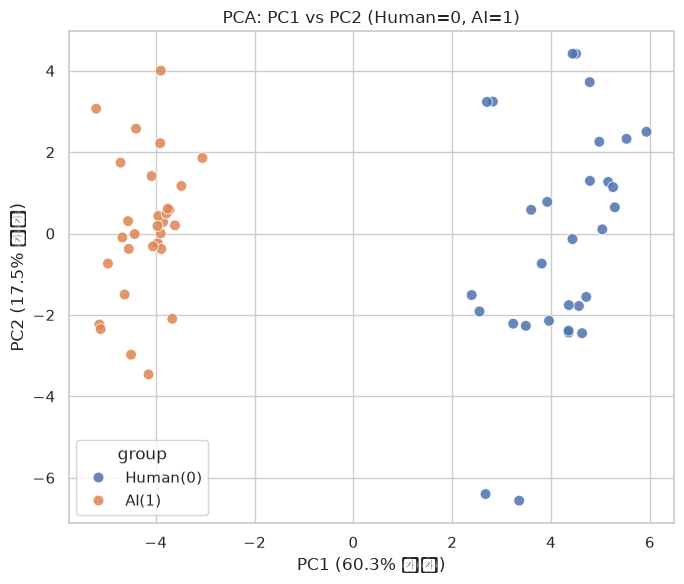

주의: PCA는 비지도학습이다. PC1/PC2에서 두 집단이 겹쳐 보인다고 해서 'AI와 인간은 구분되지 않는다'고 단정하지 않는다 (연구설계 §23). 분류 가능성은 SECTION 21 이후의 지도학습 모델로 별도로 확인한다.


,PC1_loading,PC2_loading
max_sentence_length,0.232378,-0.032070
punctuation_rate,-0.232008,0.024176
avg_word_length,-0.231879,0.039739
sentence_length_std,0.227601,-0.040939
pronoun_ratio,0.226978,-0.055407
verb_ratio,0.226127,-0.066187
three_item_enumeration_rate,-0.225681,0.055965
noun_ratio,-0.214097,0.064177
avg_sentence_length,0.213341,0.025573
particle_ratio,0.212217,0.021823


In [18]:
# ============================================================
# SECTION 20. PCA 시각화
# ============================================================
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(x=pca_scores[:, 0], y=pca_scores[:, 1], hue=y_all,
                 palette={0: "#4C72B0", 1: "#DD8452"}, ax=ax, alpha=0.85, s=60)
ax.set_xlabel(f"PC1 ({explained[0] * 100:.1f}% 설명)")
ax.set_ylabel(f"PC2 ({explained[1] * 100:.1f}% 설명)" if len(explained) > 1 else "PC2")
ax.set_title("PCA: PC1 vs PC2 (Human=0, AI=1)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Human(0)", "AI(1)"], title="group")
plt.tight_layout()
plt.savefig(FIG_DIR / "20_pca_scatter.png", dpi=150)
plt.show()

print("주의: PCA는 비지도학습이다. PC1/PC2에서 두 집단이 겹쳐 보인다고 해서 "
      "'AI와 인간은 구분되지 않는다'고 단정하지 않는다 (연구설계 §23). "
      "분류 가능성은 SECTION 21 이후의 지도학습 모델로 별도로 확인한다.")

loadings = pd.DataFrame(
    pca.components_[:2].T, index=FEATURE_NAMES, columns=["PC1_loading", "PC2_loading"]
)
top_pc1 = loadings.reindex(loadings["PC1_loading"].abs().sort_values(ascending=False).index)
display(top_pc1.head(10))


## SECTION 21. Group-aware train/test split 및 Cross Validation 설정

In [19]:
# ============================================================
# SECTION 21. group-aware train/test split (데이터 누수 방지, 연구설계 §9)
# ============================================================
# 같은 pair_id의 Human/AI 샘플이 train/test로 갈라지면 주제 정보가 누수된다.
# 따라서 일반 train_test_split 대신 GroupShuffleSplit을 사용한다.

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X_scaled, y_all, groups=groups_all))

X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]
groups_train = groups_all[train_idx]

overlap = set(groups_all[train_idx]) & set(groups_all[test_idx])
print(f"train {len(train_idx)}개, test {len(test_idx)}개")
print("train/test에 동시에 등장하는 pair_id 개수 (0이어야 정상):", len(overlap))
assert len(overlap) == 0, "데이터 누수! 같은 pair가 train/test에 함께 들어갔습니다."

N_SPLITS_CV = min(5, pd.Series(groups_all).nunique())
group_kfold = GroupKFold(n_splits=N_SPLITS_CV)
print(f"Group-aware {N_SPLITS_CV}-fold cross validation 준비 완료")


train 44개, test 16개
train/test에 동시에 등장하는 pair_id 개수 (0이어야 정상): 0
Group-aware 5-fold cross validation 준비 완료


## SECTION 22. Logistic Regression

In [20]:
# ============================================================
# SECTION 22. Logistic Regression (해석 가능한 baseline)
# ============================================================
log_reg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]

coef_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "standardized_coefficient": log_reg.coef_[0],
}).sort_values("standardized_coefficient", key=lambda s: s.abs(), ascending=False)

display(coef_df.head(10))
print("계수가 양수(+)면 AI(1)일 가능성을, 음수(-)면 Human(0)일 가능성을 높이는 방향이다.")


,feature,standardized_coefficient
2,sentence_length_std,-0.309285
19,pronoun_ratio,-0.307669
3,sentence_length_cv,-0.307210
4,max_sentence_length,-0.301279
7,punctuation_rate,0.287898
13,avg_word_length,0.281812
21,conjunction_ratio,0.281761
5,min_sentence_length,0.276729
16,verb_ratio,-0.271660
6,comma_rate,0.256529


계수가 양수(+)면 AI(1)일 가능성을, 음수(-)면 Human(0)일 가능성을 높이는 방향이다.


## SECTION 23. Decision Tree

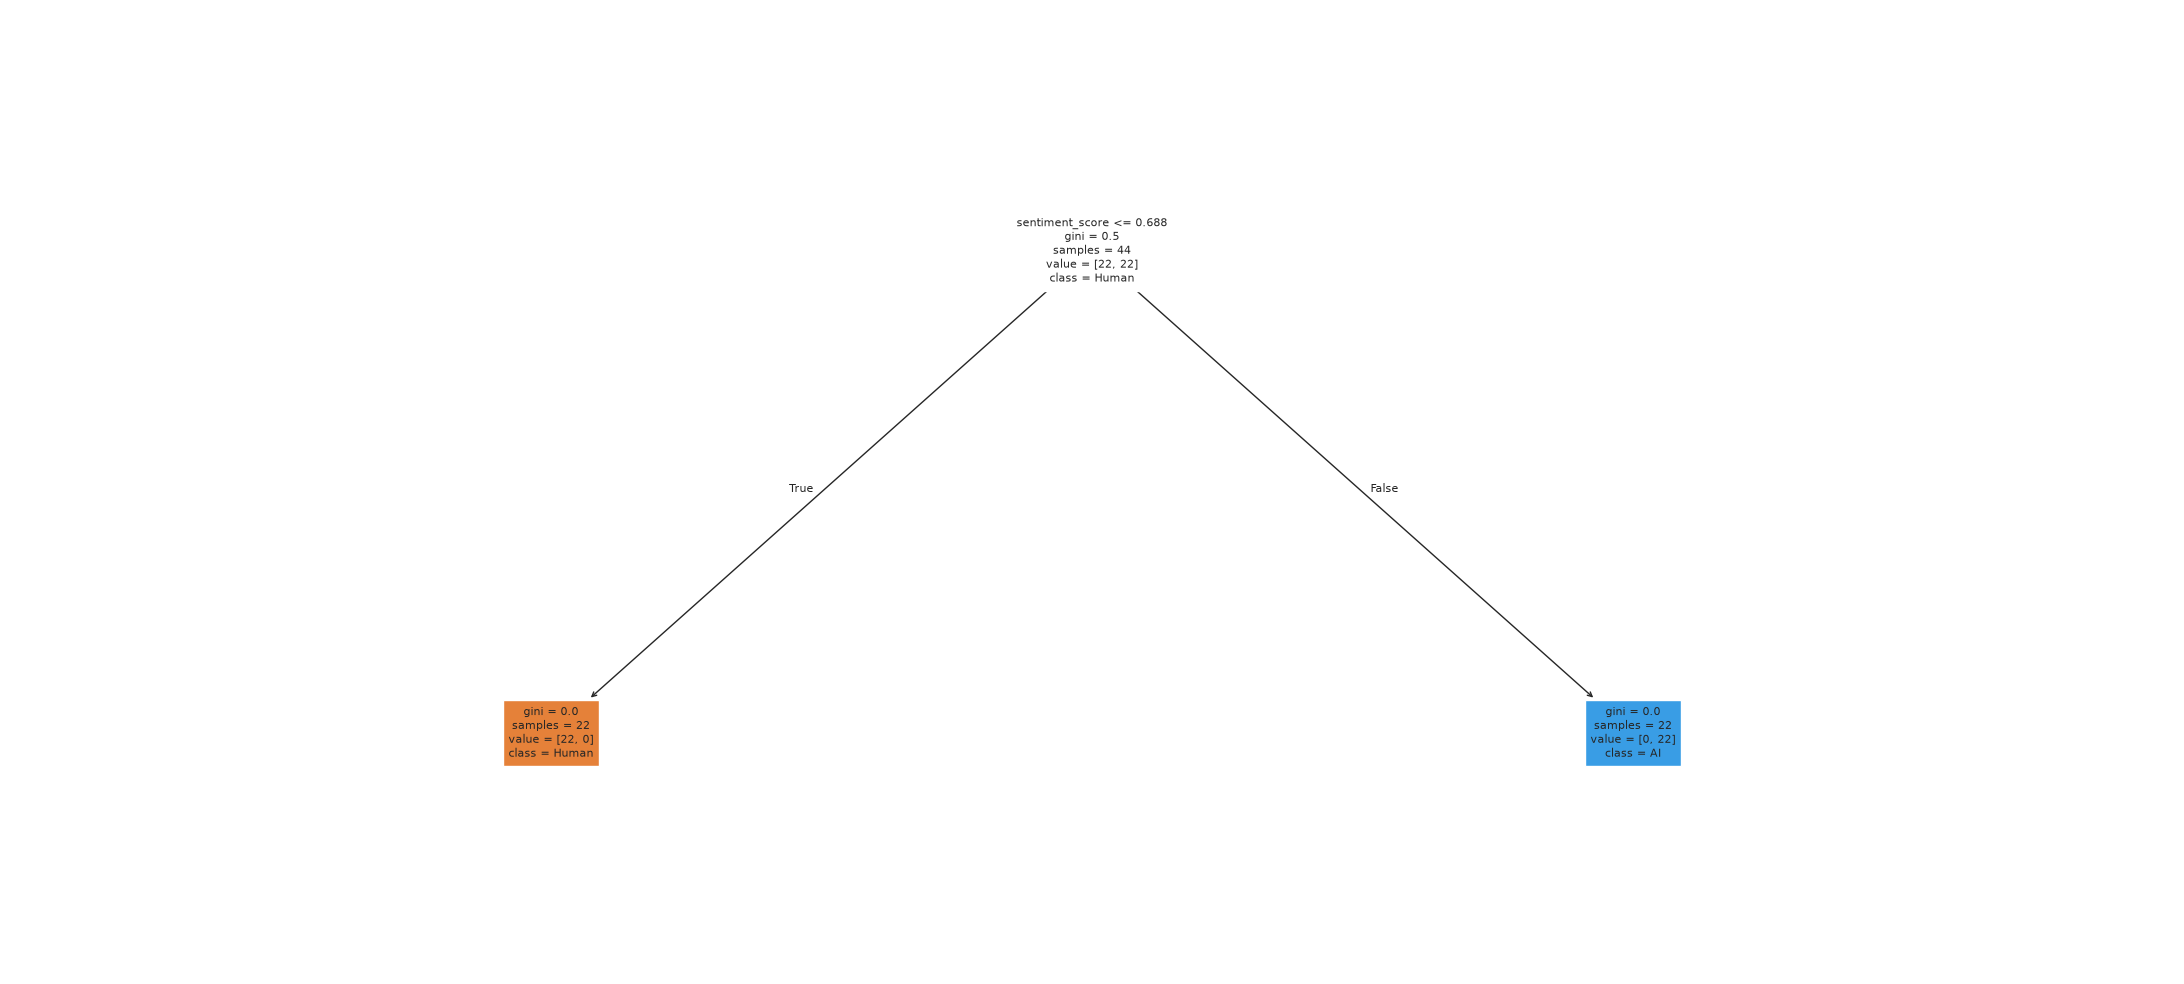

In [21]:
# ============================================================
# SECTION 23. Decision Tree (사람이 이해 가능한 분류 규칙)
# ============================================================
dt = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_proba_dt = dt.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(dt, feature_names=FEATURE_NAMES, class_names=["Human", "AI"],
          filled=True, fontsize=8, ax=ax)
plt.tight_layout()
plt.savefig(FIG_DIR / "23_decision_tree.png", dpi=150)
plt.show()


## SECTION 24. Random Forest

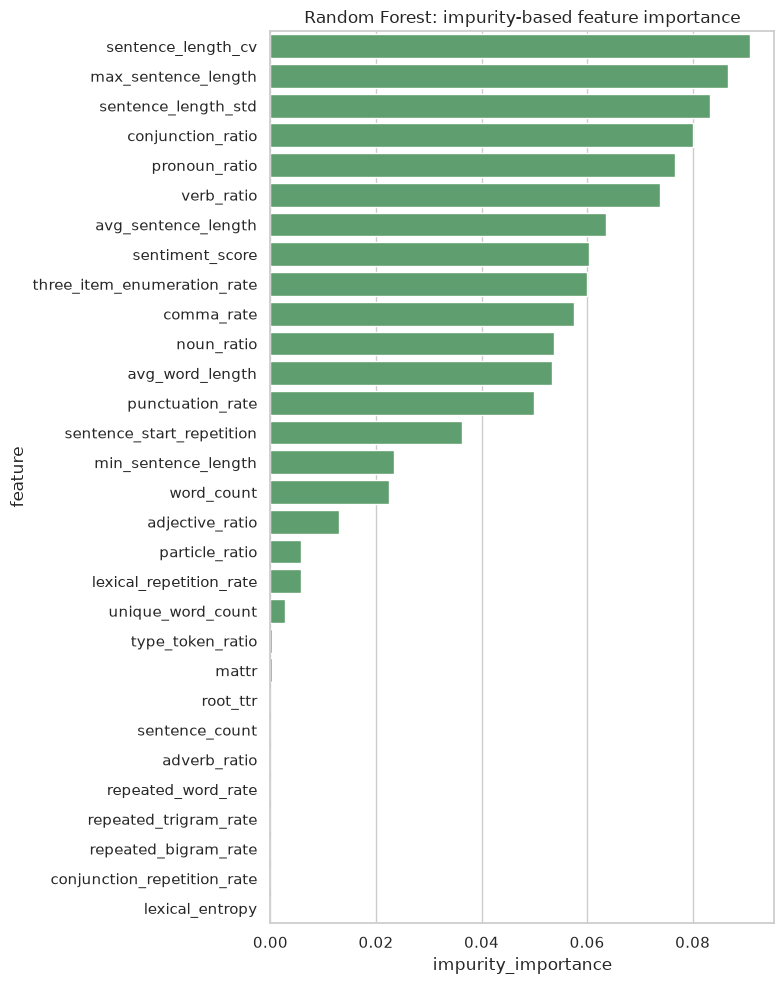

In [22]:
# ============================================================
# SECTION 24. Random Forest
# ============================================================
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

rf_importance = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "impurity_importance": rf.feature_importances_,
}).sort_values("impurity_importance", ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(data=rf_importance, y="feature", x="impurity_importance", ax=ax, color="#55A868")
ax.set_title("Random Forest: impurity-based feature importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "24_rf_importance.png", dpi=150)
plt.show()


## SECTION 25. Permutation Importance

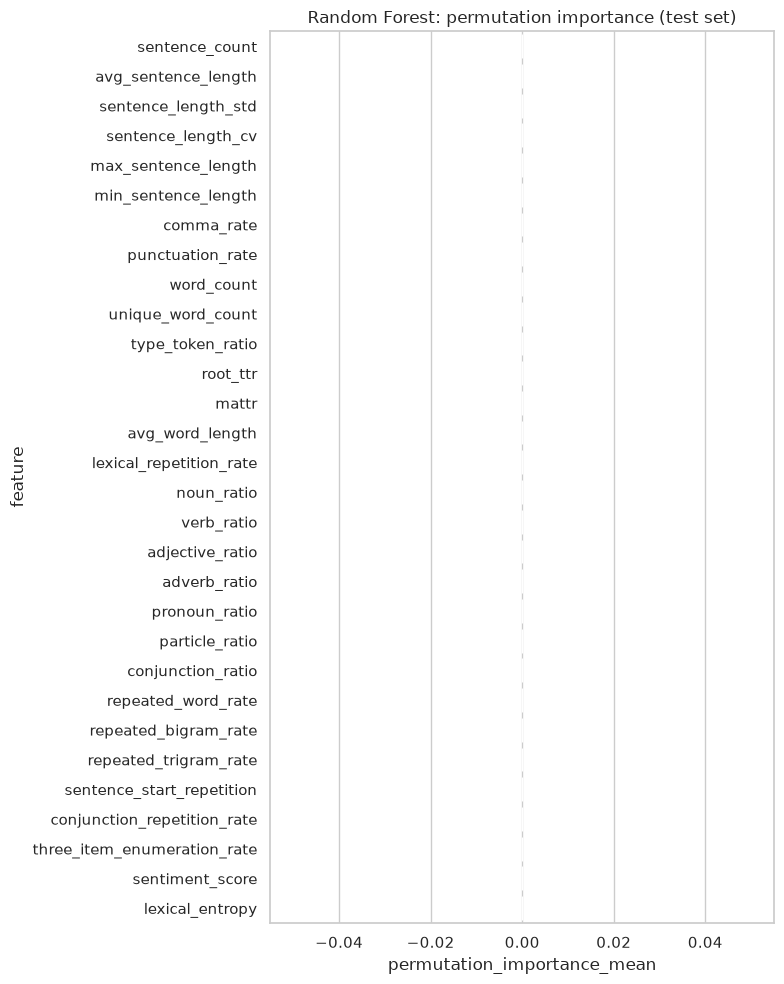

In [23]:
# ============================================================
# SECTION 25. Permutation Importance
# ============================================================
perm_result = permutation_importance(
    rf, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
perm_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "permutation_importance_mean": perm_result.importances_mean,
    "permutation_importance_std": perm_result.importances_std,
}).sort_values("permutation_importance_mean", ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(data=perm_df, y="feature", x="permutation_importance_mean", ax=ax, color="#8172B2")
ax.set_title("Random Forest: permutation importance (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "25_permutation_importance.png", dpi=150)
plt.show()


## SECTION 26. SHAP

,feature,mean_abs_shap
3,sentence_length_cv,0.045882
4,max_sentence_length,0.043333
2,sentence_length_std,0.041667
21,conjunction_ratio,0.040000
19,pronoun_ratio,0.038333
16,verb_ratio,0.037442
1,avg_sentence_length,0.032326
28,sentiment_score,0.030259
27,three_item_enumeration_rate,0.030000
6,comma_rate,0.027481


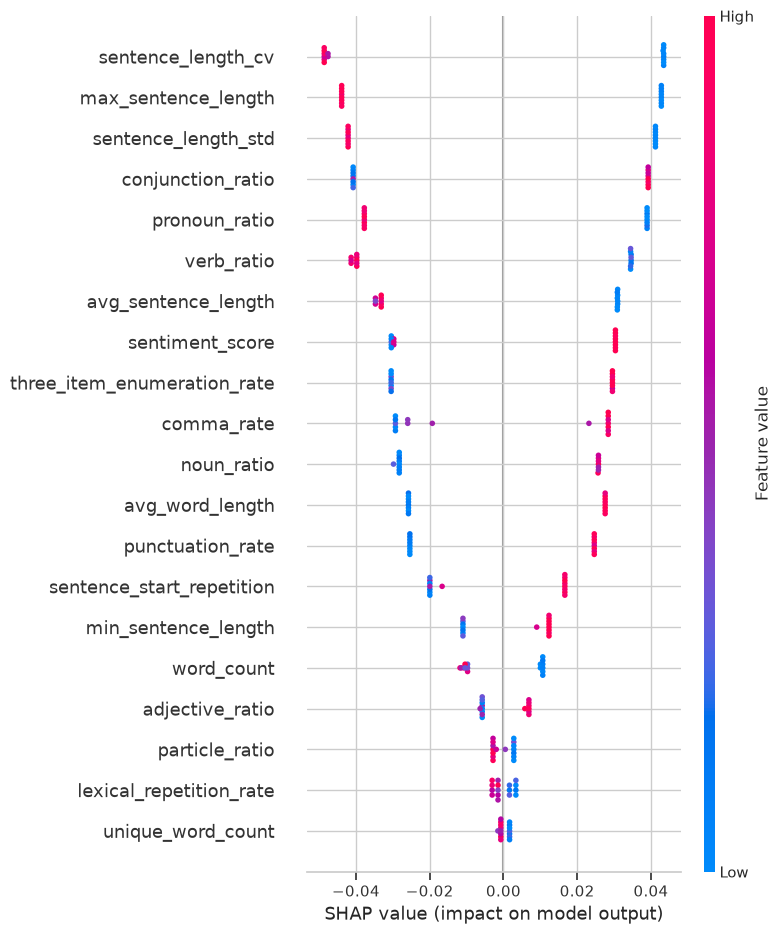

SHAP summary plot 해석: 점이 오른쪽(양의 SHAP)에 많이 몰려 있고 색이 빨간색(값이 큼)이면 그 feature의 값이 클수록 AI(1)로 분류될 가능성이 커진다는 뜻이다.


In [24]:
# ============================================================
# SECTION 26. SHAP
# ============================================================
explainer = shap.TreeExplainer(rf)
raw_shap_values = explainer.shap_values(X_test)

# shap/scikit-learn 버전에 따라 반환 형태가 다를 수 있어 방어적으로 처리한다.
if isinstance(raw_shap_values, list):
    shap_values_ai = raw_shap_values[1]
elif np.ndim(raw_shap_values) == 3:
    shap_values_ai = raw_shap_values[:, :, 1]
else:
    shap_values_ai = raw_shap_values

shap_importance = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "mean_abs_shap": np.abs(shap_values_ai).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

display(shap_importance.head(10))

plt.figure(figsize=(8, 10))
shap.summary_plot(shap_values_ai, X_test, feature_names=FEATURE_NAMES, show=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "26_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

print("SHAP summary plot 해석: 점이 오른쪽(양의 SHAP)에 많이 몰려 있고 색이 빨간색(값이 큼)이면 "
      "그 feature의 값이 클수록 AI(1)로 분류될 가능성이 커진다는 뜻이다.")


## SECTION 27. ANN (Keras)

I0000 00:00:1788949555.217430    2463 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788949555.767673    2463 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788949558.602851    2463 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


ANN 학습 종료 (실제 진행된 epoch 수: 200 / 최대 200)


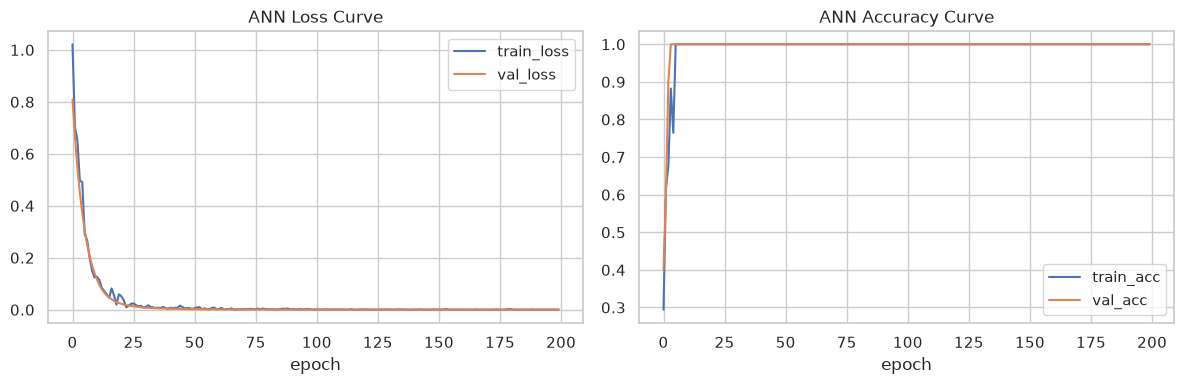

주의: 데이터가 크지 않으므로(§24 원칙) ANN이 가장 높은 정확도를 보이더라도 그것을 최종 결론 모델로 삼지 않는다. ANN의 역할은 '분류 가능성 확인'까지다.


In [25]:
# ============================================================
# SECTION 27. ANN
# ============================================================
from tensorflow import keras
from tensorflow.keras import layers, callbacks

keras.utils.set_random_seed(RANDOM_STATE)

# train 안에서 다시 group-aware하게 validation을 분리한다 (같은 pair가 train/val로 갈라지지 않도록).
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, val_idx = next(gss_val.split(X_train, y_train, groups=groups_train))
X_tr, X_val = X_train[tr_idx], X_train[val_idx]
y_tr, y_val = y_train[tr_idx], y_train[val_idx]

ann_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
ann_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

history = ann_model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=200, batch_size=8,
    callbacks=[early_stop], verbose=0,
)

print(f"ANN 학습 종료 (실제 진행된 epoch 수: {len(history.history['loss'])} / 최대 200)")

y_proba_ann = ann_model.predict(X_test, verbose=0).ravel()
y_pred_ann = (y_proba_ann >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train_loss")
axes[0].plot(history.history["val_loss"], label="val_loss")
axes[0].set_title("ANN Loss Curve")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train_acc")
axes[1].plot(history.history["val_accuracy"], label="val_acc")
axes[1].set_title("ANN Accuracy Curve")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "27_ann_training_curves.png", dpi=150)
plt.show()

print("주의: 데이터가 크지 않으므로(§24 원칙) ANN이 가장 높은 정확도를 보이더라도 "
      "그것을 최종 결론 모델로 삼지 않는다. ANN의 역할은 '분류 가능성 확인'까지다.")


## SECTION 28. 모델별 평가 및 비교

,model,accuracy,precision,recall,f1,roc_auc,cv_accuracy_mean,cv_accuracy_std
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0,1.0,0.0
1,Decision Tree,1.0,1.0,1.0,1.0,1.0,NaN,NaN
2,Random Forest,1.0,1.0,1.0,1.0,1.0,1.0,0.0
3,ANN,1.0,1.0,1.0,1.0,1.0,NaN,NaN


저장 완료: /home/user/Minbub_GUide/ai_human_stylometry/results/model_comparison.csv


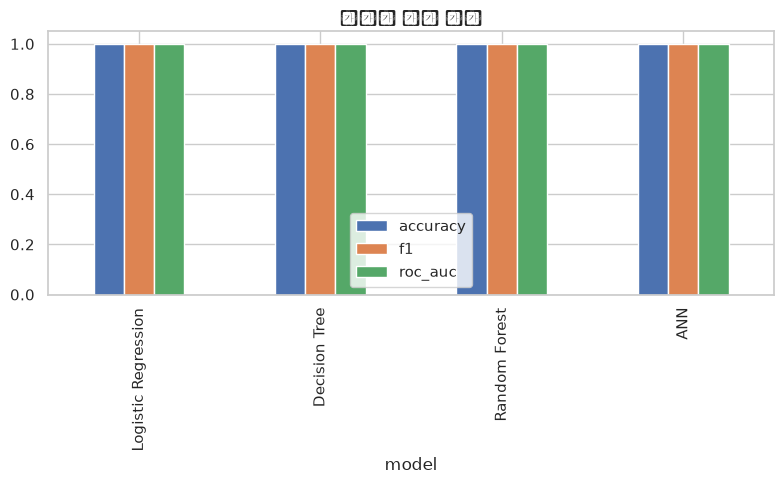

In [26]:
# ============================================================
# SECTION 28. 모델별 평가 (Accuracy/Precision/Recall/F1/ROC-AUC + group-aware CV)
# ============================================================

def evaluate(y_true, y_pred, y_proba, model_name):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba) if len(set(y_true)) > 1 else np.nan,
    }


eval_rows = [
    evaluate(y_test, y_pred_lr, y_proba_lr, "Logistic Regression"),
    evaluate(y_test, y_pred_dt, y_proba_dt, "Decision Tree"),
    evaluate(y_test, y_pred_rf, y_proba_rf, "Random Forest"),
    evaluate(y_test, y_pred_ann, y_proba_ann, "ANN"),
]
model_comparison = pd.DataFrame(eval_rows)


def group_cv_scores(model, X, y, groups, cv):
    scores = cross_val_score(model, X, y, groups=groups, cv=cv, scoring="accuracy")
    return scores.mean(), scores.std()


lr_cv_mean, lr_cv_std = group_cv_scores(
    LogisticRegression(max_iter=2000), X_scaled, y_all, groups_all, group_kfold
)
rf_cv_mean, rf_cv_std = group_cv_scores(
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), X_scaled, y_all, groups_all, group_kfold
)

model_comparison.loc[model_comparison.model == "Logistic Regression", "cv_accuracy_mean"] = lr_cv_mean
model_comparison.loc[model_comparison.model == "Logistic Regression", "cv_accuracy_std"] = lr_cv_std
model_comparison.loc[model_comparison.model == "Random Forest", "cv_accuracy_mean"] = rf_cv_mean
model_comparison.loc[model_comparison.model == "Random Forest", "cv_accuracy_std"] = rf_cv_std

display(model_comparison)
model_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", RESULTS_DIR / "model_comparison.csv")

fig, ax = plt.subplots(figsize=(8, 5))
model_comparison.set_index("model")[["accuracy", "f1", "roc_auc"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("모델별 성능 비교")
plt.tight_layout()
plt.savefig(FIG_DIR / "28_model_comparison.png", dpi=150)
plt.show()


## SECTION 29. Confusion Matrix

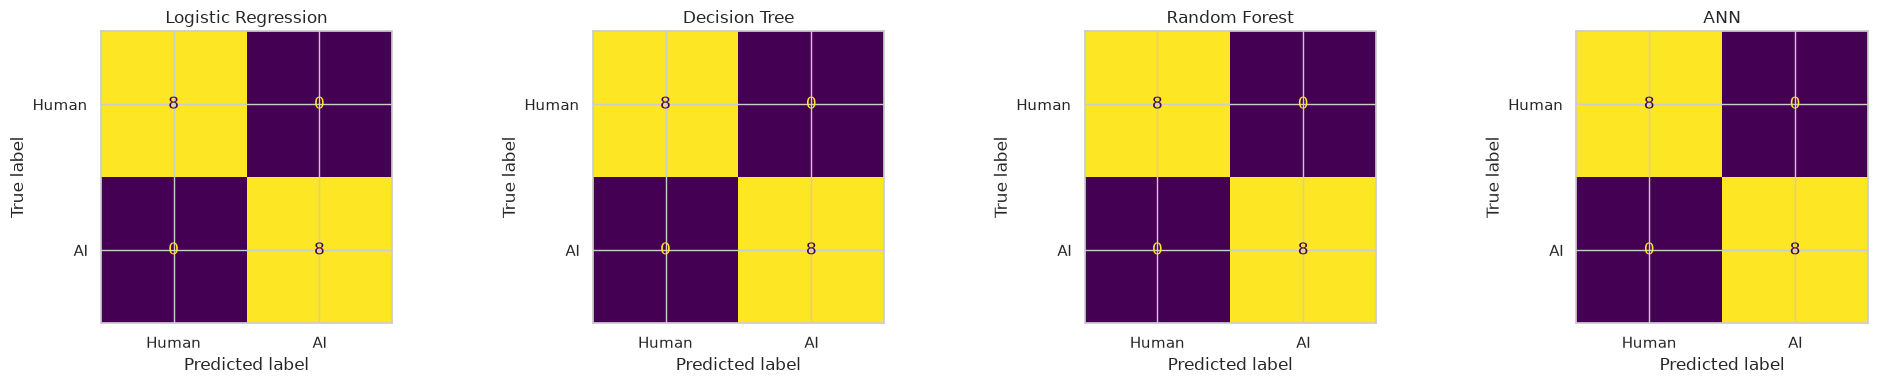

In [27]:
# ============================================================
# SECTION 29. Confusion Matrix
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
preds = {
    "Logistic Regression": y_pred_lr, "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf, "ANN": y_pred_ann,
}
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Human", "AI"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(FIG_DIR / "29_confusion_matrices.png", dpi=150)
plt.show()


## SECTION 30. ROC Curve

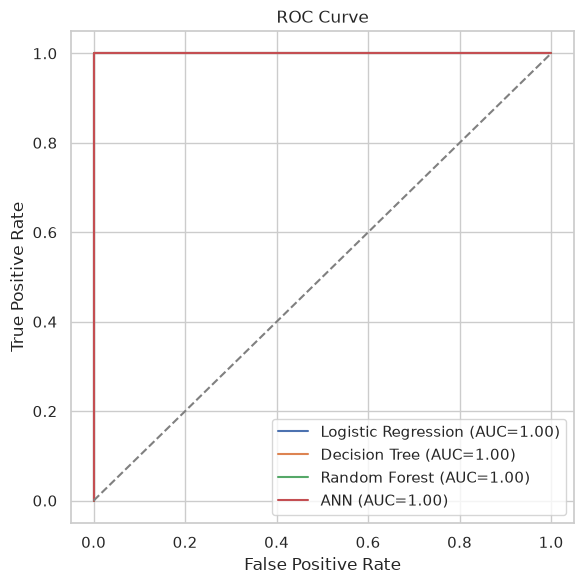

In [28]:
# ============================================================
# SECTION 30. ROC Curve
# ============================================================
fig, ax = plt.subplots(figsize=(6, 6))
probas = {
    "Logistic Regression": y_proba_lr, "Decision Tree": y_proba_dt,
    "Random Forest": y_proba_rf, "ANN": y_proba_ann,
}
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "30_roc_curve.png", dpi=150)
plt.show()


## SECTION 31. AI 모델별 추가 분석

In [29]:
# ============================================================
# SECTION 31. AI 모델별 추가 분석 (ChatGPT/Claude/Gemini 등 여러 모델을 쓴 경우)
# ============================================================
n_ai_models = analysis_df.loc[analysis_df["label"] == 1, "ai_model"].nunique()
print("현재 데이터의 AI 모델 종류 수:", n_ai_models)

if n_ai_models > 1:
    ai_model_means = analysis_df[analysis_df["label"] == 1].groupby("ai_model")[FEATURE_NAMES].mean()
    display(ai_model_means)

    top_var_features = ai_model_means.var().sort_values(ascending=False).head(6).index.tolist()
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, feat in zip(axes.flat, top_var_features):
        ai_model_means[feat].plot(kind="bar", ax=ax, color="#C44E52")
        ax.set_title(feat)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "31_ai_model_comparison.png", dpi=150)
    plt.show()
else:
    print(
        "현재 데이터에는 AI 모델이 1종류뿐이라 모델 간 비교를 생략합니다. "
        "여러 AI 모델(ChatGPT/Claude/Gemini 등)로 데이터가 확장되면 이 셀이 "
        "자동으로 모델별 feature 평균 비교표와 그래프를 출력합니다 (연구설계 §34)."
    )


현재 데이터의 AI 모델 종류 수: 1
현재 데이터에는 AI 모델이 1종류뿐이라 모델 간 비교를 생략합니다. 여러 AI 모델(ChatGPT/Claude/Gemini 등)로 데이터가 확장되면 이 셀이 자동으로 모델별 feature 평균 비교표와 그래프를 출력합니다 (연구설계 §34).


## SECTION 32. genre/domain별 robustness analysis (도메인 hold-out)

In [30]:
# ============================================================
# SECTION 32. genre/domain별 강건성 검증 (domain hold-out)
# ============================================================
# 특정 도메인 전체를 test로 남기고 나머지 도메인으로 학습한 모델이 그 도메인에서도
# AI/Human을 구분하는지 확인한다. 모델이 '분야 특성'이 아니라 '일반적인 AI/인간
# 문체 차이'를 학습했는지 점검하는 것이 목적이다 (연구설계 §9.1).

domain_counts = analysis_df["domain"].value_counts()
print("도메인별 샘플 수:")
print(domain_counts)

domain_results = []
for held_out_domain in domain_counts.index:
    train_mask = analysis_df["domain"] != held_out_domain
    test_mask = analysis_df["domain"] == held_out_domain
    if train_mask.sum() < 10 or test_mask.sum() < 4:
        continue
    if analysis_df.loc[test_mask, "label"].nunique() < 2:
        continue

    local_scaler = StandardScaler()
    Xd_train = local_scaler.fit_transform(analysis_df.loc[train_mask, FEATURE_NAMES])
    Xd_test = local_scaler.transform(analysis_df.loc[test_mask, FEATURE_NAMES])
    yd_train = analysis_df.loc[train_mask, "label"]
    yd_test = analysis_df.loc[test_mask, "label"]

    clf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
    clf.fit(Xd_train, yd_train)
    acc = accuracy_score(yd_test, clf.predict(Xd_test))
    domain_results.append({
        "held_out_domain": held_out_domain,
        "train_n": int(train_mask.sum()), "test_n": int(test_mask.sum()),
        "accuracy_on_heldout_domain": acc,
    })

domain_robustness_df = pd.DataFrame(domain_results)
if len(domain_robustness_df):
    display(domain_robustness_df)
    domain_robustness_df.to_csv(RESULTS_DIR / "domain_robustness.csv", index=False, encoding="utf-8-sig")
    print("저장 완료:", RESULTS_DIR / "domain_robustness.csv")
else:
    print("도메인별 샘플 수가 너무 적어(hold-out 기준 미충족) 강건성 검증을 생략했습니다. "
          "데이터가 300+300으로 확장되면 도메인당 샘플 수가 늘어나 이 분석이 정상적으로 실행됩니다.")


도메인별 샘플 수:
domain
environment    10
history        10
economics      10
education      10
art            10
society        10
Name: count, dtype: int64


,held_out_domain,train_n,test_n,accuracy_on_heldout_domain
0,environment,50,10,1.0
1,history,50,10,1.0
2,economics,50,10,1.0
3,education,50,10,1.0
4,art,50,10,1.0
5,society,50,10,1.0


저장 완료: /home/user/Minbub_GUide/ai_human_stylometry/results/domain_robustness.csv


## SECTION 33. 최종 Feature Importance 종합표

In [31]:
# ============================================================
# SECTION 33. 최종 Feature Importance 표 (여러 방법 종합)
# ============================================================
# Random Forest importance 하나만 보지 않고 effect size, logistic 계수, permutation
# importance, SHAP을 모두 종합해 순위를 매긴다 (연구설계 §42).

def normalize_rank(series: pd.Series) -> pd.Series:
    return series.rank(ascending=False, method="average")


master = stat_df.set_index("feature")[
    ["human_mean", "ai_mean", "mean_diff(AI-Human)", "effect_size", "p_value", "p_adjusted_fdr"]
].copy()
master = master.join(coef_df.set_index("feature")["standardized_coefficient"])
master = master.join(rf_importance.set_index("feature")["impurity_importance"])
master = master.join(perm_df.set_index("feature")["permutation_importance_mean"])
master = master.join(shap_importance.set_index("feature")["mean_abs_shap"])

rank_df = pd.DataFrame({
    "rank_effect_size": normalize_rank(master["effect_size"].abs()),
    "rank_impurity": normalize_rank(master["impurity_importance"]),
    "rank_permutation": normalize_rank(master["permutation_importance_mean"]),
    "rank_shap": normalize_rank(master["mean_abs_shap"]),
})
master["combined_rank_score"] = rank_df.mean(axis=1)
master = master.sort_values("combined_rank_score")
master["interpretation"] = np.where(
    master["mean_diff(AI-Human)"] > 0, "AI에서 더 높음", "Human에서 더 높음"
)

master_reset = master.reset_index().rename(columns={"index": "feature"})
master_reset.insert(0, "rank", range(1, len(master_reset) + 1))

display(master_reset)
master_reset.to_csv(RESULTS_DIR / "feature_importance.csv", index=False, encoding="utf-8-sig")

top10 = master_reset.head(10)
top10.to_csv(RESULTS_DIR / "top10_features.csv", index=False, encoding="utf-8-sig")
print("저장 완료: feature_importance.csv, top10_features.csv")
display(top10)


,rank,feature,human_mean,ai_mean,mean_diff(AI-Human),effect_size,p_value,p_adjusted_fdr,standardized_coefficient,impurity_importance,permutation_importance_mean,mean_abs_shap,combined_rank_score,interpretation
0,1,sentence_length_cv,0.652737,0.131326,-0.521410,-3.403930,1.090698e-17,6.544190e-17,-0.307210,0.090861,0.0,0.045882,5.625,Human에서 더 높음
1,2,pronoun_ratio,0.104356,0.011507,-0.092848,-7.118965,1.313028e-26,1.313028e-25,-0.307669,0.076667,0.0,0.038333,7.125,Human에서 더 높음
2,3,verb_ratio,0.209259,0.114586,-0.094674,-4.572673,3.413043e-21,2.559782e-20,-0.271660,0.073889,0.0,0.037442,7.875,Human에서 더 높음
3,4,conjunction_ratio,0.050875,0.108919,0.058044,2.284903,3.242797e-13,8.843992e-13,0.281761,0.080000,0.0,0.040000,8.625,AI에서 더 높음
4,5,avg_sentence_length,24.049762,12.436111,-11.613651,-2.888234,8.451091e-16,4.225545e-15,-0.253976,0.063635,0.0,0.032326,8.875,Human에서 더 높음
5,6,max_sentence_length,39.833333,14.600000,-25.233333,1.000000,1.551996e-06,2.586660e-06,-0.301279,0.086667,0.0,0.043333,9.500,Human에서 더 높음
6,7,sentence_length_std,15.124676,1.634511,-13.490165,1.000000,1.862645e-09,3.725290e-09,-0.309285,0.083333,0.0,0.041667,10.000,Human에서 더 높음
7,8,avg_word_length,4.298874,6.301591,2.002718,8.817677,2.903616e-29,8.710847e-28,0.281812,0.053333,0.0,0.026667,10.125,AI에서 더 높음
8,9,punctuation_rate,11.869850,34.238188,22.368338,7.173068,1.058363e-26,1.313028e-25,0.287898,0.050000,0.0,0.025000,10.875,AI에서 더 높음
9,10,comma_rate,1.811362,3.037037,1.225675,2.608182,1.174552e-14,3.915175e-14,0.256529,0.057473,0.0,0.027481,11.125,AI에서 더 높음


저장 완료: feature_importance.csv, top10_features.csv


,rank,feature,human_mean,ai_mean,mean_diff(AI-Human),effect_size,p_value,p_adjusted_fdr,standardized_coefficient,impurity_importance,permutation_importance_mean,mean_abs_shap,combined_rank_score,interpretation
0,1,sentence_length_cv,0.652737,0.131326,-0.521410,-3.403930,1.090698e-17,6.544190e-17,-0.307210,0.090861,0.0,0.045882,5.625,Human에서 더 높음
1,2,pronoun_ratio,0.104356,0.011507,-0.092848,-7.118965,1.313028e-26,1.313028e-25,-0.307669,0.076667,0.0,0.038333,7.125,Human에서 더 높음
2,3,verb_ratio,0.209259,0.114586,-0.094674,-4.572673,3.413043e-21,2.559782e-20,-0.271660,0.073889,0.0,0.037442,7.875,Human에서 더 높음
3,4,conjunction_ratio,0.050875,0.108919,0.058044,2.284903,3.242797e-13,8.843992e-13,0.281761,0.080000,0.0,0.040000,8.625,AI에서 더 높음
4,5,avg_sentence_length,24.049762,12.436111,-11.613651,-2.888234,8.451091e-16,4.225545e-15,-0.253976,0.063635,0.0,0.032326,8.875,Human에서 더 높음
5,6,max_sentence_length,39.833333,14.600000,-25.233333,1.000000,1.551996e-06,2.586660e-06,-0.301279,0.086667,0.0,0.043333,9.500,Human에서 더 높음
6,7,sentence_length_std,15.124676,1.634511,-13.490165,1.000000,1.862645e-09,3.725290e-09,-0.309285,0.083333,0.0,0.041667,10.000,Human에서 더 높음
7,8,avg_word_length,4.298874,6.301591,2.002718,8.817677,2.903616e-29,8.710847e-28,0.281812,0.053333,0.0,0.026667,10.125,AI에서 더 높음
8,9,punctuation_rate,11.869850,34.238188,22.368338,7.173068,1.058363e-26,1.313028e-25,0.287898,0.050000,0.0,0.025000,10.875,AI에서 더 높음
9,10,comma_rate,1.811362,3.037037,1.225675,2.608182,1.174552e-14,3.915175e-14,0.256529,0.057473,0.0,0.027481,11.125,AI에서 더 높음


## SECTION 34. 최종 결과 자동 요약

In [32]:
# ============================================================
# SECTION 34. 분석 결과 자동 요약 (Results 초안 생성)
# ============================================================
# 실제 데이터로 이 노트북을 실행하면, 아래 함수가 실제 수치를 채워 넣은 요약을 만든다.
# 과장된 표현(§14 원칙)을 피하고, 항상 '본 데이터셋과 분석 조건에서'로 문장을 시작한다.

def generate_results_summary() -> str:
    lines = []
    lines.append("## 자동 생성 결과 요약 (Results 초안)\n")
    if USE_SYNTHETIC_DEMO:
        lines.append(
            f"**⚠️ 아래 수치는 SYNTHETIC DEMO 데이터(절차적으로 생성한 더미 텍스트, N={len(analysis_df)})로 "
            "파이프라인이 정상 작동하는지 확인한 결과다. 실제 AI/인간 문체 차이에 대한 연구 결과가 "
            "아니므로 논문에 인용하면 안 된다. USE_SYNTHETIC_DEMO=False로 바꾸고 실제 600개 데이터 "
            "경로를 지정한 뒤 다시 실행하면, 이 자리에 실제 연구 결과가 채워진다.**\n"
        )
    n_human = int((analysis_df["label"] == 0).sum())
    n_ai = int((analysis_df["label"] == 1).sum())
    lines.append(f"- 총 {len(analysis_df)}개 샘플(Human {n_human}개, AI {n_ai}개)을 분석했다.")
    n_sig = int(stat_df["significant_fdr_0.05"].sum())
    lines.append(f"- FDR 보정 후 유의(p_adjusted<0.05)했던 feature는 {n_sig}/{len(stat_df)}개였다.")
    if len(cumulative) > 1:
        lines.append(f"- PCA 상위 2개 주성분은 전체 분산의 {cumulative[1] * 100:.1f}%를 설명했다.")

    best_model_row = model_comparison.sort_values("accuracy", ascending=False).iloc[0]
    lines.append(
        f"- 가장 높은 accuracy를 보인 모델은 {best_model_row['model']} "
        f"(accuracy={best_model_row['accuracy']:.2f}, F1={best_model_row['f1']:.2f}, "
        f"ROC-AUC={best_model_row['roc_auc']:.2f})였다. 다만 연구설계 원칙상 이는 "
        "'가장 우수한 모델'이 아니라 '분류 가능성의 확인'으로 해석한다."
    )

    top3_names = master_reset.head(3)["feature"].tolist()
    lines.append(
        f"- effect size·Random Forest importance·permutation importance·SHAP을 종합했을 때 "
        f"상위 3개 변수는 {', '.join(top3_names)}였다."
    )
    for feat in top3_names:
        row = master_reset[master_reset["feature"] == feat].iloc[0]
        lines.append(
            f"  - **{feat}**: 본 데이터셋과 분석 조건에서 {row['interpretation']}의 경향을 보였다 "
            f"(Human 평균={row['human_mean']:.3f}, AI 평균={row['ai_mean']:.3f})."
        )

    lines.append("\n### 결론 작성 시 주의 (연구설계 §14)")
    lines.append(
        "- 위 결과는 '본 데이터셋과 분석 조건'에서의 경향으로만 해석하며, 모든 언어·장르·AI 모델에 "
        "일반화된다고 단정하지 않는다."
    )
    lines.append(
        "- '문장력이 떨어진다/우월하다/창의성이 없다'와 같은 가치판단으로 결과를 확장하지 않는다."
    )
    return "\n".join(lines)


summary_text = generate_results_summary()
print(summary_text)

with open(RESULTS_DIR / "auto_generated_results_summary.md", "w", encoding="utf-8") as f:
    f.write(summary_text)
print("\n저장 완료:", RESULTS_DIR / "auto_generated_results_summary.md")


## 자동 생성 결과 요약 (Results 초안)

**⚠️ 아래 수치는 SYNTHETIC DEMO 데이터(절차적으로 생성한 더미 텍스트, N=60)로 파이프라인이 정상 작동하는지 확인한 결과다. 실제 AI/인간 문체 차이에 대한 연구 결과가 아니므로 논문에 인용하면 안 된다. USE_SYNTHETIC_DEMO=False로 바꾸고 실제 600개 데이터 경로를 지정한 뒤 다시 실행하면, 이 자리에 실제 연구 결과가 채워진다.**

- 총 60개 샘플(Human 30개, AI 30개)을 분석했다.
- FDR 보정 후 유의(p_adjusted<0.05)했던 feature는 28/30개였다.
- PCA 상위 2개 주성분은 전체 분산의 77.8%를 설명했다.
- 가장 높은 accuracy를 보인 모델은 Logistic Regression (accuracy=1.00, F1=1.00, ROC-AUC=1.00)였다. 다만 연구설계 원칙상 이는 '가장 우수한 모델'이 아니라 '분류 가능성의 확인'으로 해석한다.
- effect size·Random Forest importance·permutation importance·SHAP을 종합했을 때 상위 3개 변수는 sentence_length_cv, pronoun_ratio, verb_ratio였다.
  - **sentence_length_cv**: 본 데이터셋과 분석 조건에서 Human에서 더 높음의 경향을 보였다 (Human 평균=0.653, AI 평균=0.131).
  - **pronoun_ratio**: 본 데이터셋과 분석 조건에서 Human에서 더 높음의 경향을 보였다 (Human 평균=0.104, AI 평균=0.012).
  - **verb_ratio**: 본 데이터셋과 분석 조건에서 Human에서 더 높음의 경향을 보였다 (Human 평균=0.209, AI 평균=0.115).

### 결론 작성 시 주의 (연구설계 §14)
- 위 결과는 '본 데이터셋과 분석 조건'에서의 경향으로만 해석하며, 모든 언어·장르·AI 모델

## 마무리: 이 노트북을 실제 연구에 쓰려면

1. `docs/research_design.md` §12(STEP 계획)에 따라 Human corpus를 25개 단위 batch로
   구축하고, **원문을 1차 자료와 대조 검증**한 뒤 `verified: true`로 바꾸고
   `excerpt_text`를 채운다. (`data/human_classic/batch01_human_classic.jsonl`이
   서지정보가 확정된 첫 batch다 — 검증만 남았다.)
2. `src/prompt_builder.py`의 `build_ai_prompt()`로 각 Human 샘플에 대응하는 AI 생성
   프롬프트를 만들고, 실제 AI 모델(ChatGPT/Claude/Gemini 등)에 입력해 AI corpus를
   생성한다. (`data/ai_generated/batch01_ai_generated.jsonl`이 그 예시다.)
3. Human 300개 + AI 300개가 모이면 `human_classic_full.jsonl` /
   `ai_generated_full.jsonl`로 합치고, SECTION 3의 `USE_SYNTHETIC_DEMO = False`로
   바꾼 뒤 **Run All**을 실행한다.
4. `results/` 폴더에 CSV 결과표(6종)와 `results/figures/`에 그래프(PNG)가 자동으로
   쌓인다. `results/auto_generated_results_summary.md`를 논문 Results/Discussion
   초안의 출발점으로 사용한다.
